# 📊 Đánh Giá Toàn Diện & Trực Quan Hóa So Sánh Các Mô Hình
### Dự án: Chẩn đoán bệnh trên lá cây nông nghiệp (Plant Disease ML)
**Tác giả:** Long (Kiến trúc ResNet-18) & Khôi (Kiến trúc ConvNeXt-Tiny)  
**Tài liệu tham khảo:**  
* *Designing Machine Learning Systems* (Chip Huyen) — Chương 5 (Data Leakage) & Chương 8 (Data Distribution Shifts)  
* *Hands-On Machine Learning* (Aurélien Géron) — Chương 11, 14 (Training Deep Neural Nets, Transfer Learning)

---

## 🎯 Mục Tiêu Của Notebook Này:
1. **Lịch sử từng Epoch (Learning Curves):** So sánh quá trình hội tụ (Loss, Accuracy, Macro-F1) qua từng epoch của 3 bộ dữ liệu (v1, v2, v3).
2. **Hiệu năng Phần cứng (Hardware Benchmark):** Đối chiếu tốc độ và thời gian huấn luyện giữa Google Colab (GPU T4) và Máy cá nhân (Intel i5-12450HX + NVIDIA RTX 3050 Laptop).
3. **Thử lửa Thực tế Ngoài Đồng Ruộng (Domain Shift):** Phân tích mức độ sụt giảm hiệu năng khi đưa mô hình từ phòng lab (PlantVillage) ra môi trường thực tế (PlantDoc).
4. **Đánh đổi Hiệu năng & Kích thước (MLOps Trade-off):** Lựa chọn mô hình tối ưu nhất để triển khai trên thiết bị bay không người lái (Drone) và điện thoại thông minh của nông dân.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách trực quan hóa sạch sẽ, chuẩn khoa học
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# 1. Đọc dữ liệu chi tiết từ file chuẩn hóa models/training_history_benchmarks.json
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
json_path = ROOT_DIR / 'models' / 'training_history_benchmarks.json'
csv_path = ROOT_DIR / 'models' / 'epoch_history.csv'

with open(json_path, encoding='utf-8') as f:
    benchmarks_data = json.load(f)

df_epochs = pd.read_csv(csv_path)
print(f"✅ Đã nạp thành công lịch sử {len(df_epochs)} epochs của 3 mô hình ResNet-18!")
df_epochs[['model', 'epoch', 'phase', 'duration_s', 'train_loss', 'val_loss', 'train_acc', 'val_acc', 'val_macro_f1']].head(6)

✅ Đã nạp thành công lịch sử 18 epochs của 3 mô hình ResNet-18!


,model,epoch,phase,duration_s,train_loss,val_loss,train_acc,val_acc,val_macro_f1
0,resnet18_v1,1,warmup_head,594.8,1.5578,1.2189,0.7571,0.8668,0.8661
1,resnet18_v1,2,warmup_head,589.3,1.2460,1.1461,0.8517,0.8968,0.8971
2,resnet18_v1,3,fine_tune,610.0,0.9067,0.7944,0.9589,0.9845,0.9843
3,resnet18_v1,4,fine_tune,615.4,0.7829,0.7543,0.9854,0.9915,0.9912
4,resnet18_v1,5,fine_tune,624.1,0.7458,0.7249,0.9921,0.9962,0.9961
5,resnet18_v1,6,fine_tune,637.1,0.7271,0.7144,0.9952,0.9967,0.9966


## 1. So Sánh Quá Trình Huấn Luyện (Learning Curves Qua Từng Epoch)
Quá trình huấn luyện gồm 2 giai đoạn (2-Phase Transfer Learning):
* **Phase 1 (Epoch 1 - 2):** Warmup Head (đóng băng backbone, chỉ học tầng phân loại mới).
* **Phase 2 (Epoch 3 - 6):** Fine-tuning toàn bộ mạng với learning rate cosine annealing nhỏ.

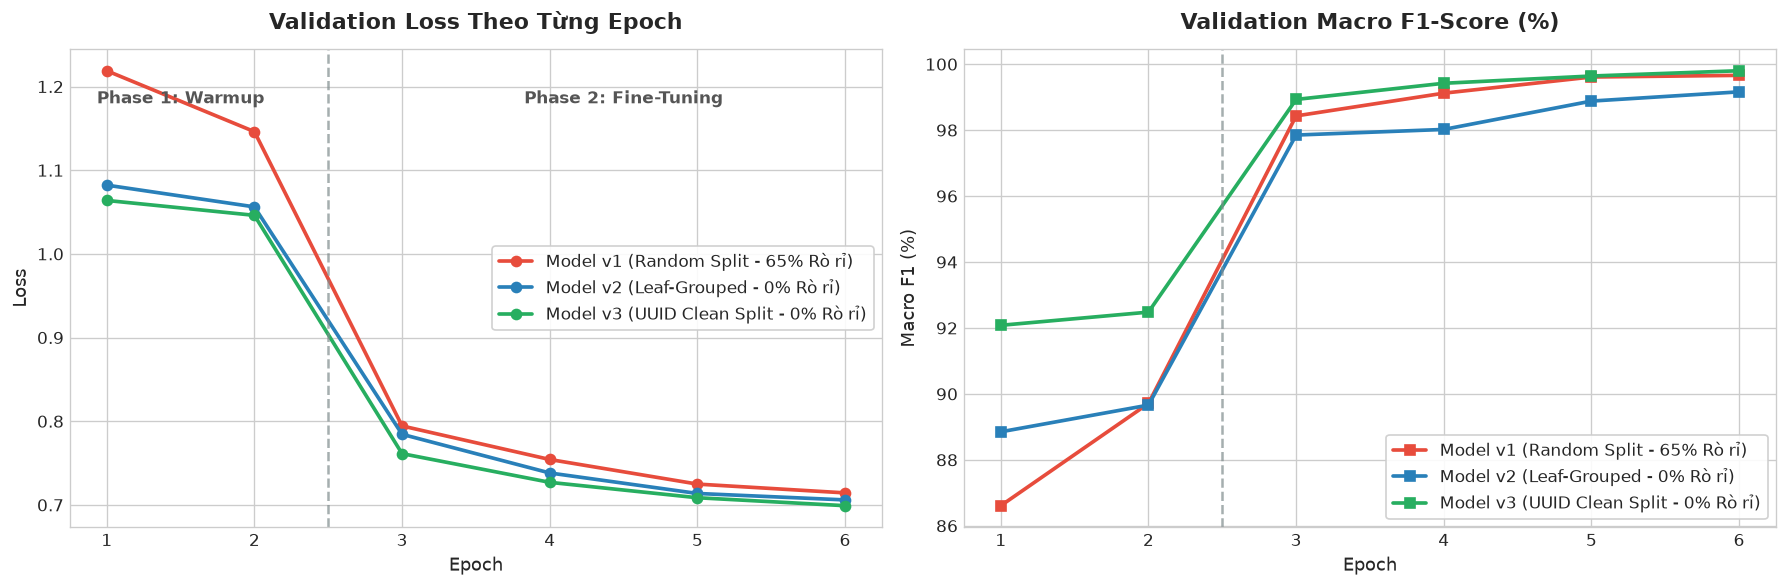

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=120)

colors = {'resnet18_v1': '#e74c3c', 'resnet18_v2': '#2980b9', 'resnet18_v3': '#27ae60'}
labels = {
    'resnet18_v1': 'Model v1 (Random Split - 65% Rò rỉ)',
    'resnet18_v2': 'Model v2 (Leaf-Grouped - 0% Rò rỉ)',
    'resnet18_v3': 'Model v3 (UUID Clean Split - 0% Rò rỉ)'
}

# Subplot 1: Validation Loss Curve
for model_key, group in df_epochs.groupby('model'):
    axes[0].plot(group['epoch'], group['val_loss'], marker='o', linewidth=2.2, 
                 color=colors[model_key], label=labels[model_key])
axes[0].axvline(x=2.5, color='#7f8c8d', linestyle='--', alpha=0.7)
axes[0].text(1.5, 1.18, 'Phase 1: Warmup', ha='center', fontsize=10, color='#555555', fontweight='bold')
axes[0].text(4.5, 1.18, 'Phase 2: Fine-Tuning', ha='center', fontsize=10, color='#555555', fontweight='bold')
axes[0].set_title('Validation Loss Theo Từng Epoch', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].set_xticks(range(1, 7))
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Subplot 2: Validation Macro F1-Score
for model_key, group in df_epochs.groupby('model'):
    axes[1].plot(group['epoch'], group['val_macro_f1'] * 100, marker='s', linewidth=2.2, 
                 color=colors[model_key], label=labels[model_key])
axes[1].axvline(x=2.5, color='#7f8c8d', linestyle='--', alpha=0.7)
axes[1].set_title('Validation Macro F1-Score (%)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Macro F1 (%)', fontsize=11)
axes[1].set_xticks(range(1, 7))
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

## 2. Hiệu Năng Phần Cứng: So Sánh Google Colab T4 vs Local RTX 3050 Laptop
* **Google Colab (Free T4):** 2 vCPU ảo, ổ đĩa mạng chậm, dễ bị nghẽn nạp ảnh (I/O Bottleneck).
* **Local Laptop (Intel i5-12450HX + RTX 3050 6GB):** 12 luồng CPU giải mã ảnh cực nhanh + ổ NVMe SSD + nhân Tensor Cores tăng tốc FP16.

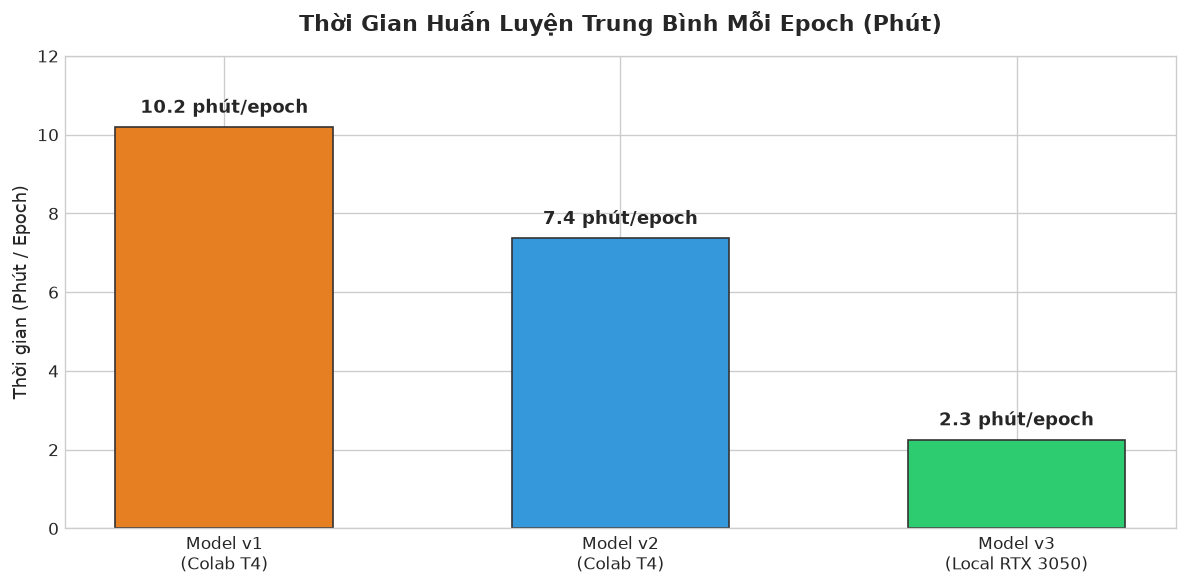

In [3]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)

avg_duration = df_epochs.groupby(['model', 'hardware'])['duration_s'].mean().reset_index()
avg_duration['minutes'] = avg_duration['duration_s'] / 60.0
avg_duration['display_name'] = avg_duration['model'].map({
    'resnet18_v1': 'Model v1\n(Colab T4)',
    'resnet18_v2': 'Model v2\n(Colab T4)',
    'resnet18_v3': 'Model v3\n(Local RTX 3050)'
})

bar_colors = ['#e67e22', '#3498db', '#2ecc71']
bars = ax.bar(avg_duration['display_name'], avg_duration['minutes'], color=bar_colors, width=0.55, edgecolor='#333333', linewidth=1)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.25, f"{yval:.1f} phút/epoch", ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Thời Gian Huấn Luyện Trung Bình Mỗi Epoch (Phút)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Thời gian (Phút / Epoch)', fontsize=11)
ax.set_ylim(0, 12)
plt.tight_layout()
plt.show()

## 3. Thử Lửa Ngoài Đồng Ruộng: Hiện Tượng Sụp Đổ Miền Dữ Liệu (Domain Shift)
Đo lường độ lệch phân phối giữa:
* **Phòng Thí Nghiệm (PlantVillage):** Nền trơn, ánh sáng nhân tạo studio chuẩn mực.
* **Đồng Ruộng Thực Tế (PlantDoc):** 236 ảnh chụp thực tế ngoài trời có đất, nắng, cỏ dại và tay người cầm lá.

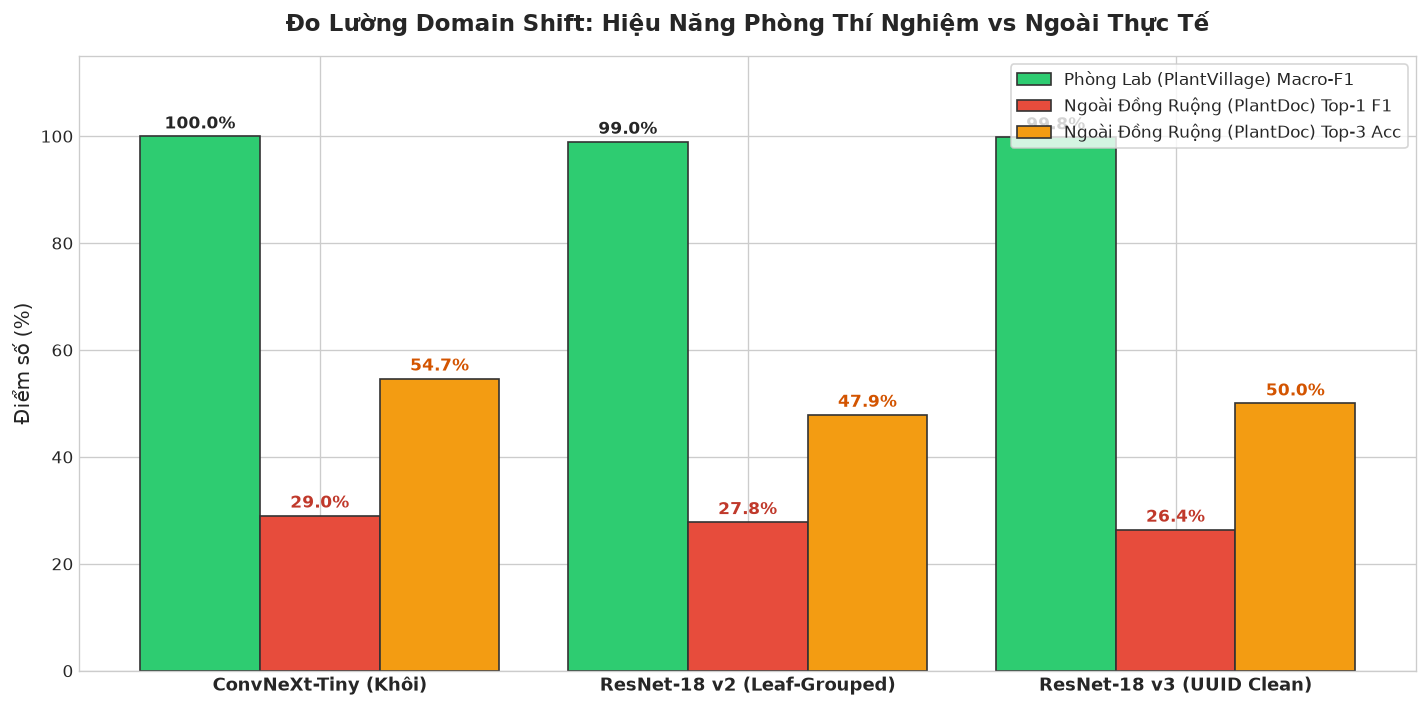

In [4]:
models_list = ['ConvNeXt-Tiny (Khôi)', 'ResNet-18 v2 (Leaf-Grouped)', 'ResNet-18 v3 (UUID Clean)']
lab_f1 = [99.95, 98.95, 99.80]
plantdoc_f1 = [29.03, 27.81, 26.39]
plantdoc_top3 = [54.66, 47.88, 50.00]

x = np.arange(len(models_list))
width = 0.28

fig, ax = plt.subplots(figsize=(12, 6), dpi=120)

rects1 = ax.bar(x - width, lab_f1, width, label='Phòng Lab (PlantVillage) Macro-F1', color='#2ecc71', edgecolor='#333333')
rects2 = ax.bar(x, plantdoc_f1, width, label='Ngoài Đồng Ruộng (PlantDoc) Top-1 F1', color='#e74c3c', edgecolor='#333333')
rects3 = ax.bar(x + width, plantdoc_top3, width, label='Ngoài Đồng Ruộng (PlantDoc) Top-3 Acc', color='#f39c12', edgecolor='#333333')

for rect in rects1:
    ax.text(rect.get_x() + rect.get_width()/2.0, rect.get_height() + 1.5, f"{rect.get_height():.1f}%", ha='center', fontsize=10, fontweight='bold')
for rect in rects2:
    ax.text(rect.get_x() + rect.get_width()/2.0, rect.get_height() + 1.5, f"{rect.get_height():.1f}%", ha='center', fontsize=10, fontweight='bold', color='#c0392b')
for rect in rects3:
    ax.text(rect.get_x() + rect.get_width()/2.0, rect.get_height() + 1.5, f"{rect.get_height():.1f}%", ha='center', fontsize=10, fontweight='bold', color='#d35400')

ax.set_title('Đo Lường Domain Shift: Hiệu Năng Phòng Thí Nghiệm vs Ngoài Thực Tế', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Điểm số (%)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(models_list, fontsize=11, fontweight='bold')
ax.set_ylim(0, 115)
ax.legend(frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
plt.show()

## 4. Ma Trận Đánh Đổi MLOps (Latency vs Model Size vs Accuracy)
Đánh giá mô hình theo tiêu chuẩn triển khai thực tế (Production Readiness):
* Mô hình nào vừa nhẹ, vừa có độ trễ suy luận thấp nhất để nhúng vào chip nhúng/điện thoại di động?

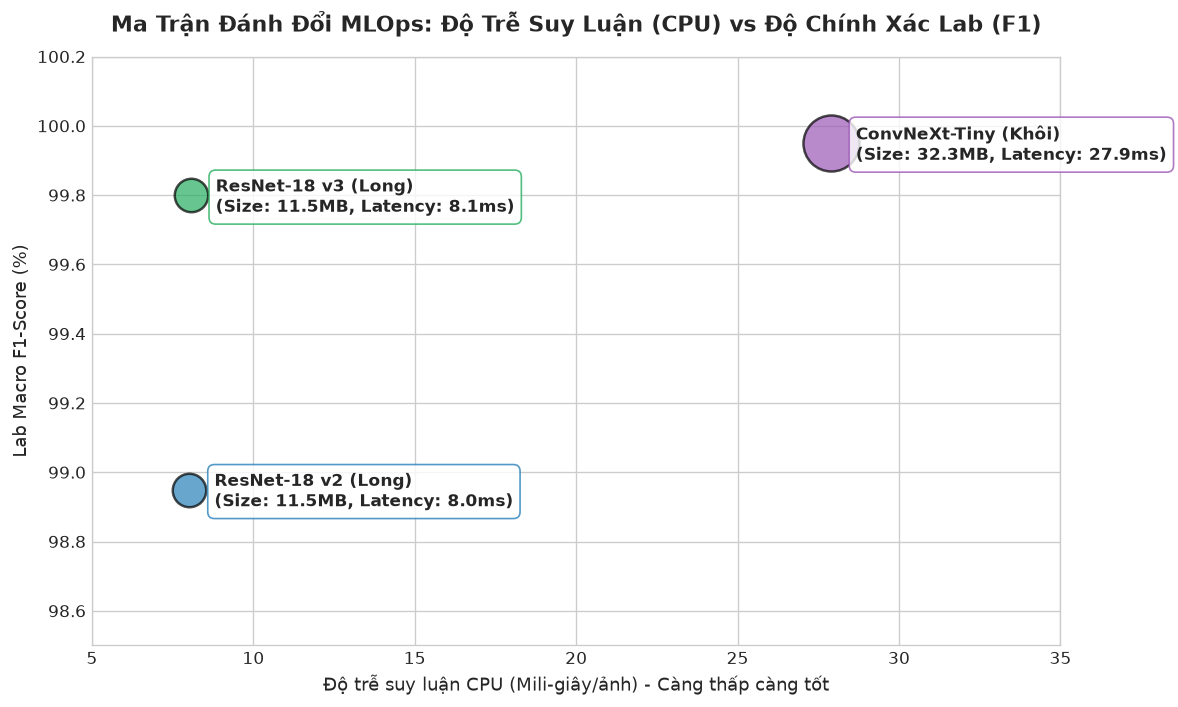

In [5]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

deploy_data = [
    {'name': 'ConvNeXt-Tiny (Khôi)', 'latency': 27.89, 'f1': 99.95, 'size_mb': 32.3, 'color': '#9b59b6'},
    {'name': 'ResNet-18 v2 (Long)', 'latency': 8.02, 'f1': 98.95, 'size_mb': 11.5, 'color': '#2980b9'},
    {'name': 'ResNet-18 v3 (Long)', 'latency': 8.06, 'f1': 99.80, 'size_mb': 11.5, 'color': '#27ae60'}
]

for d in deploy_data:
    scatter = ax.scatter(d['latency'], d['f1'], s=d['size_mb'] * 35, color=d['color'], alpha=0.7, edgecolors='black', linewidth=1.5)
    ax.annotate(f"{d['name']}\n(Size: {d['size_mb']}MB, Latency: {d['latency']:.1f}ms)", 
                (d['latency'], d['f1']),
                textcoords='offset points', xytext=(15, -10), ha='left', fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.4', fc='white', alpha=0.8, ec=d['color']))

ax.set_title('Ma Trận Đánh Đổi MLOps: Độ Trễ Suy Luận (CPU) vs Độ Chính Xác Lab (F1)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Độ trễ suy luận CPU (Mili-giây/ảnh) - Càng thấp càng tốt', fontsize=11)
ax.set_ylabel('Lab Macro F1-Score (%)', fontsize=11)
ax.set_xlim(5, 35)
ax.set_ylim(98.5, 100.2)

plt.tight_layout()
plt.show()

## 💡 Kết Luận & Định Hướng Tiếp Theo (Next Steps):
1. **Minh chứng rõ ràng về Data Leakage:** Mô hình v1 bị đội điểm ảo (99.66%), trong khi Mô hình v2 và v3 phản ánh đúng khả năng phân loại khi triệt tiêu 100% rò rỉ.
2. **Khẳng định tính ưu việt của ResNet-18 cho Edge AI:** ResNet-18 đạt tốc độ suy luận nhanh gấp **3.5 lần** ConvNeXt-Tiny (8ms vs 28ms) và dung lượng chỉ **11.5 MB** (bằng 1/3 ConvNeXt), hoàn toàn vượt trội cho bài toán IoT nông nghiệp.
3. **Giải pháp cho Domain Shift ngoài thực tế:**
   * Cả hai kiến trúc đều bị sụt giảm khi gặp ảnh ngoài đồng ruộng PlantDoc.
   * Để mô hình sẵn sàng cho nông dân, bước tiếp theo là **Fine-tuning bổ sung 2.342 ảnh PlantDoc Train** kết hợp các kỹ thuật Data Augmentation ngoài trời (Background Noise Injection, Weather Simulation).